In [2]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import ConcatDataset, DataLoader, random_split

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 20
PATIENCE = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Device:", DEVICE)

Device: cpu


In [6]:
transform = torchvision.transforms.ToTensor()

train_data = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)

test_data = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

dataset = ConcatDataset([train_data, test_data])

n_train = int(0.8 * len(dataset))
n_val = int(0.1 * len(dataset))
n_test = len(dataset) - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

val_loader = DataLoader(
    val_set, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_set, batch_size=BATCH_SIZE, shuffle=False
)

print("Train:", len(train_set))
print("Validation:", len(val_set))
print("Test:", len(test_set))

Train: 56000
Validation: 7000
Test: 7000


In [41]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def encode(self, x):
        x = x.view(x.size(0), 784)
        x = F.relu(self.fc1(x))
        return F.relu(self.fc2(x))

    def forward(self, x):
        return self.fc3(self.encode(x))


class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(64, 256)
        self.fc2 = nn.Linear(256, 784)

    def forward(self, z):
        return torch.sigmoid(self.fc2(F.relu(self.fc1(z))))


class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder1 = nn.Linear(784, 256)
        self.encoder2 = nn.Linear(256, 64)
        self.decoder1 = nn.Linear(64, 256)
        self.decoder2 = nn.Linear(256, 784)

    def encode(self, x):
        x = F.relu(self.encoder1(x.view(x.size(0), 784)))
        return F.relu(self.encoder2(x))

    def forward(self, x):
        z = self.encode(x)
        return torch.sigmoid(
            self.decoder2(F.relu(self.decoder1(z)))
        )

In [75]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.view(images.size(0), 784).to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def train_classifier(model, train_loader, val_loader):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_state = copy.deepcopy(model.state_dict())
    best_acc = -1.0
    stale = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_loss, total = 0.0, 0

        for images, labels in train_loader:
            images = images.view(images.size(0), 784).to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            total += labels.size(0)

        val_loss, val_acc = evaluate_classifier(model, val_loader)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss / total:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2%}"
        )

        if val_acc > best_acc:
            best_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(best_state)
    return model


def forward_reconstruction(model, x, encoder=None):
    if encoder is None:
        return model(x)

    with torch.no_grad():
        z = encoder.encode(x)

    return model(z)


def train_reconstructor(
    model, train_loader, val_loader,
    encoder=None, return_history=False
):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_state = copy.deepcopy(model.state_dict())
    best_loss = float("inf")
    stale = 0

    history = {
        "train": [],
        "val": []
    }

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()

        train_sum, train_count = 0.0, 0

        for images, _ in train_loader:
            x = images.view(images.size(0), 784).to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            prediction = forward_reconstruction(model, x, encoder)
            loss = F.mse_loss(prediction, x)
            loss.backward()
            optimizer.step()

            train_sum += loss.item() * x.size(0)
            train_count += x.size(0)

        train_loss = train_sum / train_count

        model.eval()
        val_sum, val_count = 0.0, 0

        with torch.no_grad():
            for images, _ in val_loader:
                x = images.view(images.size(0), 784).to(DEVICE)
                prediction = forward_reconstruction(model, x, encoder)

                loss = F.mse_loss(prediction, x)
                val_sum += loss.item() * x.size(0)
                val_count += x.size(0)

        val_loss = val_sum / val_count

        history["train"].append(train_loss)
        history["val"].append(val_loss)

        print(
            f"Epoch {epoch:02d} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(best_state)

    if return_history:
        return model, history

    return model


def reconstruction_metrics(prediction, target):
    prediction = prediction.view(-1, 1, 28, 28).to(DEVICE)
    target = target.view(-1, 1, 28, 28).to(DEVICE)

    mse = F.mse_loss(prediction, target).item()

    mse_per_image = (prediction - target).pow(2).mean(dim=(1, 2, 3))
    psnr = (
        10 * torch.log10(1.0 / mse_per_image.clamp_min(1e-12))
    ).mean().item()

    c1, c2 = 0.01**2, 0.03**2
    mu_x = F.avg_pool2d(prediction, 7, stride=1)
    mu_y = F.avg_pool2d(target, 7, stride=1)

    correction = 49 / 48

    var_x = correction * (
        F.avg_pool2d(prediction**2, 7, stride=1) - mu_x**2
    )
    var_y = correction * (
        F.avg_pool2d(target**2, 7, stride=1) - mu_y**2
    )
    cov_xy = correction * (
        F.avg_pool2d(prediction * target, 7, stride=1) - mu_x * mu_y
    )

    ssim = (
        ((2 * mu_x * mu_y + c1) * (2 * cov_xy + c2))
        / ((mu_x**2 + mu_y**2 + c1) * (var_x + var_y + c2))
    ).mean().item()

    return {"MSE": mse, "PSNR (dB)": psnr, "SSIM": ssim}


def show_grid(images, titles=None, rows=1, cols=1, figsize=(8, 4)):
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.asarray(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")

        if i < len(images):
            image = images[i]
            if isinstance(image, torch.Tensor):
                image = image.detach().cpu().numpy()

            ax.imshow(
                np.asarray(image).reshape(28, 28),
                cmap="gray",
                vmin=0,
                vmax=1
            )

            if titles is not None:
                ax.set_title(titles[i], fontsize=8)

    plt.tight_layout()
    plt.show()

In [76]:
vanilla_ae, vanilla_ae_history = train_reconstructor(
    VanillaAE().to(DEVICE),
    train_loader,
    val_loader,
    return_history=True
)

Epoch 01 | Train MSE: 0.034278 | Val MSE: 0.020078
Epoch 02 | Train MSE: 0.017556 | Val MSE: 0.016165
Epoch 03 | Train MSE: 0.014851 | Val MSE: 0.014236
Epoch 04 | Train MSE: 0.013501 | Val MSE: 0.013131
Epoch 05 | Train MSE: 0.012425 | Val MSE: 0.012238
Epoch 06 | Train MSE: 0.011674 | Val MSE: 0.011582
Epoch 07 | Train MSE: 0.011083 | Val MSE: 0.011145
Epoch 08 | Train MSE: 0.010627 | Val MSE: 0.010654
Epoch 09 | Train MSE: 0.010236 | Val MSE: 0.010276
Epoch 10 | Train MSE: 0.009880 | Val MSE: 0.009949
Epoch 11 | Train MSE: 0.009621 | Val MSE: 0.009759
Epoch 12 | Train MSE: 0.009354 | Val MSE: 0.009492
Epoch 13 | Train MSE: 0.009163 | Val MSE: 0.009328
Epoch 14 | Train MSE: 0.008969 | Val MSE: 0.009245
Epoch 15 | Train MSE: 0.008800 | Val MSE: 0.008986
Epoch 16 | Train MSE: 0.008666 | Val MSE: 0.008874
Epoch 17 | Train MSE: 0.008526 | Val MSE: 0.008799
Epoch 18 | Train MSE: 0.008429 | Val MSE: 0.008778
Epoch 19 | Train MSE: 0.008316 | Val MSE: 0.008558
Epoch 20 | Train MSE: 0.008219 

In [43]:
classifier = MLPClassifier().to(DEVICE)

classifier = train_classifier(
    classifier, train_loader, val_loader
)

_, test_accuracy = evaluate_classifier(classifier, test_loader)

print(f"MLP Test Accuracy: {test_accuracy:.2%}")

if test_accuracy < 0.88:
    print("Target akurasi test 88% belum tercapai.")

torch.save(
    {
        "W1": classifier.fc1.weight.detach().cpu(),
        "W2": classifier.fc2.weight.detach().cpu(),
        "W3": classifier.fc3.weight.detach().cpu()
    },
    "mlp_weights_W1_W2_W3.pt"
)

Epoch 01 | Train Loss: 0.6048 | Val Loss: 0.4404 | Val Acc: 84.50%
Epoch 02 | Train Loss: 0.4048 | Val Loss: 0.4030 | Val Acc: 85.34%
Epoch 03 | Train Loss: 0.3605 | Val Loss: 0.3804 | Val Acc: 86.27%
Epoch 04 | Train Loss: 0.3315 | Val Loss: 0.3712 | Val Acc: 86.31%
Epoch 05 | Train Loss: 0.3117 | Val Loss: 0.3416 | Val Acc: 87.93%
Epoch 06 | Train Loss: 0.2999 | Val Loss: 0.3365 | Val Acc: 87.64%
Epoch 07 | Train Loss: 0.2807 | Val Loss: 0.3354 | Val Acc: 87.89%
Epoch 08 | Train Loss: 0.2704 | Val Loss: 0.3325 | Val Acc: 87.64%
Epoch 09 | Train Loss: 0.2595 | Val Loss: 0.3500 | Val Acc: 87.03%
Epoch 10 | Train Loss: 0.2526 | Val Loss: 0.3218 | Val Acc: 88.63%
Epoch 11 | Train Loss: 0.2405 | Val Loss: 0.3279 | Val Acc: 88.00%
Epoch 12 | Train Loss: 0.2307 | Val Loss: 0.3096 | Val Acc: 88.87%
Epoch 13 | Train Loss: 0.2230 | Val Loss: 0.3053 | Val Acc: 89.47%
Epoch 14 | Train Loss: 0.2169 | Val Loss: 0.3235 | Val Acc: 88.63%
Epoch 15 | Train Loss: 0.2119 | Val Loss: 0.3160 | Val Acc: 89

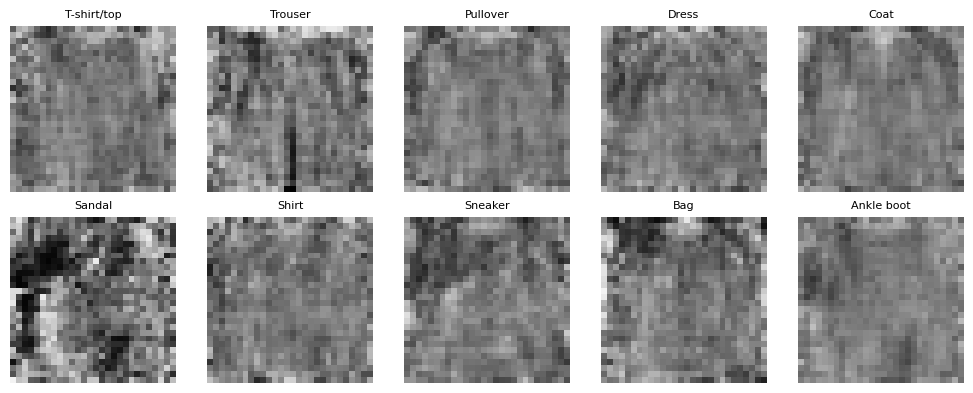

In [17]:
classifier.eval()

with torch.no_grad():
    y_onehot = torch.eye(10, device=DEVICE)

    z_hat = F.relu(
        F.linear(y_onehot, classifier.fc3.weight.T)
    )

    h_hat = F.relu(
        F.linear(z_hat, classifier.fc2.weight.T)
    )

    x_hat = torch.sigmoid(
        F.linear(h_hat, classifier.fc1.weight.T)
    ).cpu()

show_grid(
    list(x_hat),
    CLASS_NAMES,
    rows=2,
    cols=5,
    figsize=(10, 4)
)

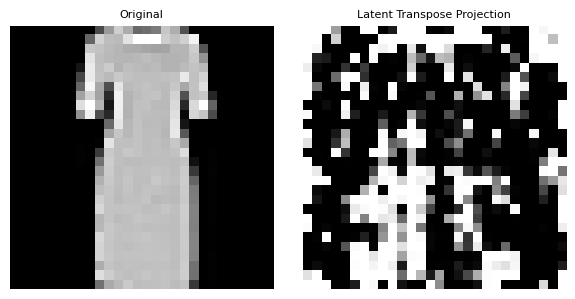

In [18]:
test_images, _ = next(iter(test_loader))
x = test_images[:1].view(1, 784).to(DEVICE)

with torch.no_grad():
    z_mlp = classifier.encode(x)

    h_hat = F.relu(
        F.linear(z_mlp, classifier.fc2.weight.T)
    )

    x_hat = torch.sigmoid(
        F.linear(h_hat, classifier.fc1.weight.T)
    )

show_grid(
    [x.cpu()[0], x_hat.cpu()[0]],
    ["Original", "Latent Transpose Projection"],
    rows=1,
    cols=2,
    figsize=(6, 3)
)

Epoch 01 | Val MSE: 0.026545
Epoch 02 | Val MSE: 0.023130
Epoch 03 | Val MSE: 0.021669
Epoch 04 | Val MSE: 0.020748
Epoch 05 | Val MSE: 0.020038
Epoch 06 | Val MSE: 0.019532
Epoch 07 | Val MSE: 0.019348
Epoch 08 | Val MSE: 0.018898
Epoch 09 | Val MSE: 0.018607
Epoch 10 | Val MSE: 0.018487
Epoch 11 | Val MSE: 0.018186
Epoch 12 | Val MSE: 0.018398
Epoch 13 | Val MSE: 0.017866
Epoch 14 | Val MSE: 0.017770
Epoch 15 | Val MSE: 0.017724
Epoch 16 | Val MSE: 0.017541
Epoch 17 | Val MSE: 0.017414
Epoch 18 | Val MSE: 0.017323
Epoch 19 | Val MSE: 0.017249
Epoch 20 | Val MSE: 0.017194
Epoch 01 | Val MSE: 0.020329
Epoch 02 | Val MSE: 0.016512
Epoch 03 | Val MSE: 0.014568
Epoch 04 | Val MSE: 0.013217
Epoch 05 | Val MSE: 0.012371
Epoch 06 | Val MSE: 0.011735
Epoch 07 | Val MSE: 0.011122
Epoch 08 | Val MSE: 0.010732
Epoch 09 | Val MSE: 0.010443
Epoch 10 | Val MSE: 0.010045
Epoch 11 | Val MSE: 0.009739
Epoch 12 | Val MSE: 0.009566
Epoch 13 | Val MSE: 0.009328
Epoch 14 | Val MSE: 0.009109
Epoch 15 | Val

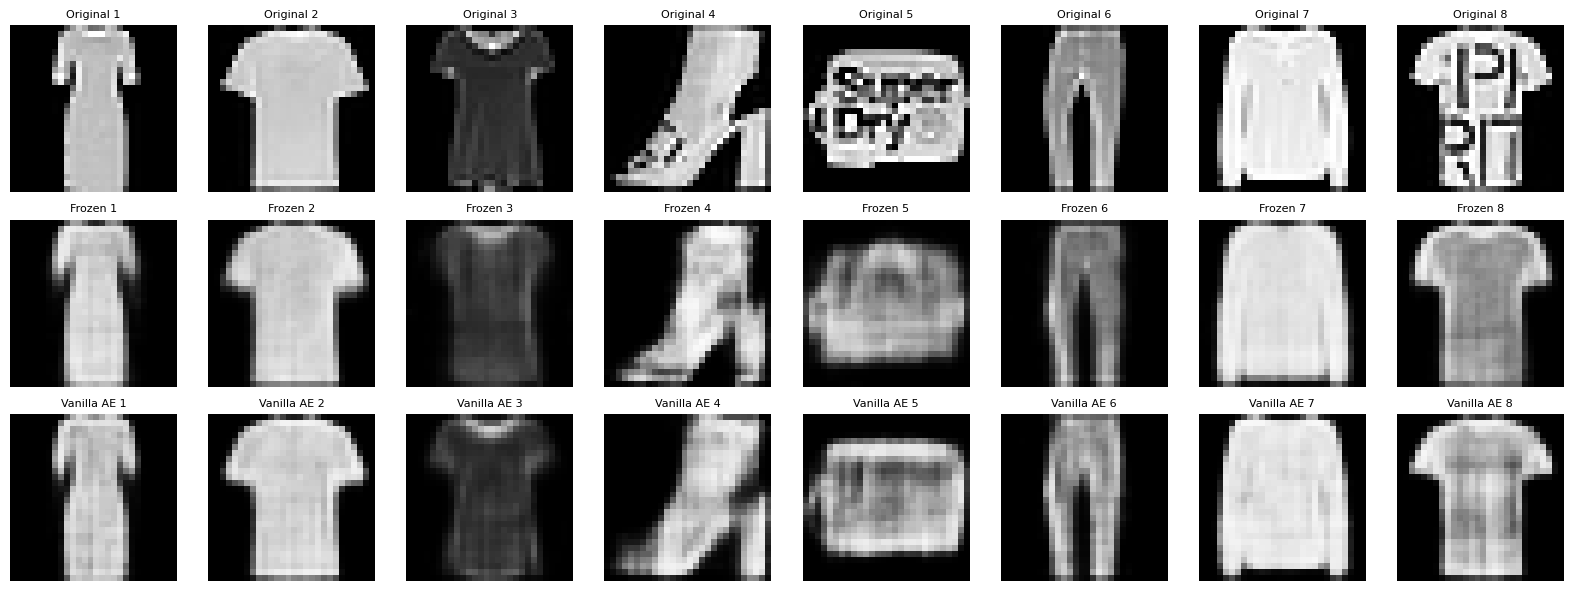

In [ ]:
for parameter in classifier.parameters():
    parameter.requires_grad = False

classifier.eval()

frozen_decoder = train_reconstructor(
    Decoder().to(DEVICE),
    train_loader,
    val_loader,
    encoder=classifier
)

vanilla_ae = train_reconstructor(
    VanillaAE().to(DEVICE),
    train_loader,
    val_loader
)


targets, frozen_outputs, ae_outputs, test_latents = [], [], [], []

with torch.no_grad():
    for images, _ in test_loader:
        x = images.view(images.size(0), 784).to(DEVICE)
        z = classifier.encode(x)

        targets.append(x.cpu())
        test_latents.append(z.cpu())
        frozen_outputs.append(frozen_decoder(z).cpu())
        ae_outputs.append(vanilla_ae(x).cpu())

targets = torch.cat(targets)
frozen_outputs = torch.cat(frozen_outputs)
ae_outputs = torch.cat(ae_outputs)

print("Frozen Latent Decoder:",
      reconstruction_metrics(frozen_outputs, targets))

print("Vanilla AE:",
      reconstruction_metrics(ae_outputs, targets))


n = 8

images = (
    list(targets[:n])
    + list(frozen_outputs[:n])
    + list(ae_outputs[:n])
)

titles = (
    [f"Original {i+1}" for i in range(n)]
    + [f"Frozen {i+1}" for i in range(n)]
    + [f"Vanilla AE {i+1}" for i in range(n)]
)

show_grid(
    images,
    titles,
    rows=3,
    cols=n,
    figsize=(16, 6)
)

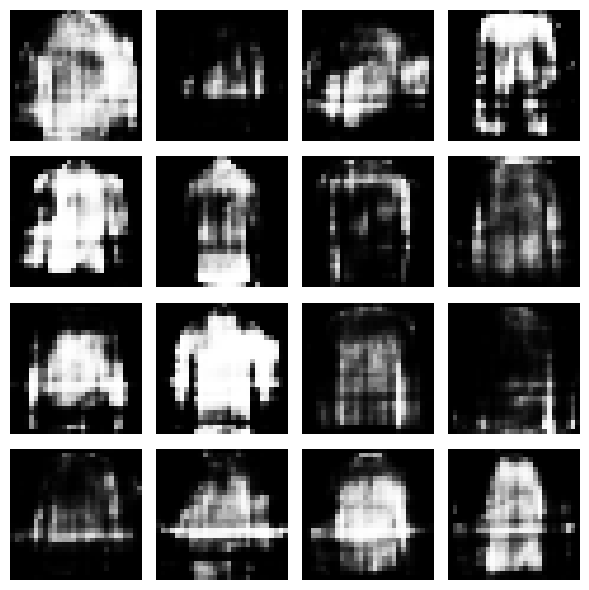

In [ ]:
z_test = torch.cat(test_latents).to(DEVICE)

mu_z = z_test.mean(dim=0)
sigma_z = z_test.std(dim=0, unbiased=False)

with torch.no_grad():
    z_random = (
        mu_z
        + torch.randn(16, 64, device=DEVICE) * sigma_z
    )

    generated_images = frozen_decoder(z_random).cpu()

show_grid(
    list(generated_images),
    rows=4,
    cols=4,
    figsize=(6, 6)
)

In [7]:
class SparseAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder1 = nn.Linear(784, 256)
        self.encoder2 = nn.Linear(256, 64)
        self.decoder1 = nn.Linear(64, 256)
        self.decoder2 = nn.Linear(256, 784)

    def encode(self, x):
        x = x.view(x.size(0), 784)
        x = F.relu(self.encoder1(x))
        return F.relu(self.encoder2(x))

    def forward(self, x):
        z = self.encode(x)
        reconstruction = torch.sigmoid(
            self.decoder2(F.relu(self.decoder1(z)))
        )
        return reconstruction, z


class VAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, 64)
        self.fc_logvar = nn.Linear(256, 64)

        self.decoder1 = nn.Linear(64, 256)
        self.decoder2 = nn.Linear(256, 784)

    def encode(self, x):
        x = x.view(x.size(0), 784)
        h = F.relu(self.encoder1(x))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return torch.sigmoid(
            self.decoder2(F.relu(self.decoder1(z)))
        )

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)

        return reconstruction, mu, logvar

In [8]:
SPARSITY_LAMBDA = 1e-4
BETA_VAE = 1.0


def train_sparse_ae(model, train_loader, val_loader):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_state = copy.deepcopy(model.state_dict())
    best_loss = float("inf")
    stale = 0
    history = {"train": [], "val": []}

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_sum, count = 0.0, 0

        for images, _ in train_loader:
            x = images.view(images.size(0), 784).to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, z = model(x)

            reconstruction_loss = F.mse_loss(reconstruction, x)
            sparsity_loss = z.abs().sum(dim=1).mean()

            loss = (
                reconstruction_loss
                + SPARSITY_LAMBDA * sparsity_loss
            )

            loss.backward()
            optimizer.step()

            train_sum += loss.item() * x.size(0)
            count += x.size(0)

        train_loss = train_sum / count

        model.eval()
        val_sum, count = 0.0, 0

        with torch.no_grad():
            for images, _ in val_loader:
                x = images.view(images.size(0), 784).to(DEVICE)

                reconstruction, z = model(x)

                reconstruction_loss = F.mse_loss(reconstruction, x)
                sparsity_loss = z.abs().sum(dim=1).mean()

                loss = (
                    reconstruction_loss
                    + SPARSITY_LAMBDA * sparsity_loss
                )

                val_sum += loss.item() * x.size(0)
                count += x.size(0)

        val_loss = val_sum / count

        history["train"].append(train_loss)
        history["val"].append(val_loss)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_loss:.5f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(best_state)
    return model, history


def vae_loss_function(reconstruction, x, mu, logvar):
    reconstruction_loss = F.binary_cross_entropy(
        reconstruction, x, reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + BETA_VAE * kl_loss


def train_vae(model, train_loader, val_loader):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    best_state = copy.deepcopy(model.state_dict())
    best_loss = float("inf")
    stale = 0
    history = {"train": [], "val": []}

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_sum, count = 0.0, 0

        for images, _ in train_loader:
            x = images.view(images.size(0), 784).to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, mu, logvar = model(x)
            loss = vae_loss_function(reconstruction, x, mu, logvar)

            loss.backward()
            optimizer.step()

            train_sum += loss.item()
            count += x.size(0)

        train_loss = train_sum / count

        model.eval()
        val_sum, count = 0.0, 0

        with torch.no_grad():
            for images, _ in val_loader:
                x = images.view(images.size(0), 784).to(DEVICE)

                reconstruction, mu, logvar = model(x)
                loss = vae_loss_function(
                    reconstruction, x, mu, logvar
                )

                val_sum += loss.item()
                count += x.size(0)

        val_loss = val_sum / count

        history["train"].append(train_loss)
        history["val"].append(val_loss)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if stale >= PATIENCE:
            break

    model.load_state_dict(best_state)
    return model, history

In [9]:
sparse_ae = SparseAE().to(DEVICE)
sparse_ae, sparse_history = train_sparse_ae(
    sparse_ae, train_loader, val_loader
)

vae = VAE().to(DEVICE)
vae, vae_history = train_vae(
    vae, train_loader, val_loader
)

Epoch 01 | Train Loss: 0.03761 | Val Loss: 0.02256
Epoch 02 | Train Loss: 0.02019 | Val Loss: 0.01887
Epoch 03 | Train Loss: 0.01755 | Val Loss: 0.01689
Epoch 04 | Train Loss: 0.01604 | Val Loss: 0.01577
Epoch 05 | Train Loss: 0.01503 | Val Loss: 0.01482
Epoch 06 | Train Loss: 0.01424 | Val Loss: 0.01420
Epoch 07 | Train Loss: 0.01366 | Val Loss: 0.01369
Epoch 08 | Train Loss: 0.01319 | Val Loss: 0.01323
Epoch 09 | Train Loss: 0.01281 | Val Loss: 0.01298
Epoch 10 | Train Loss: 0.01248 | Val Loss: 0.01267
Epoch 11 | Train Loss: 0.01222 | Val Loss: 0.01235
Epoch 12 | Train Loss: 0.01198 | Val Loss: 0.01211
Epoch 13 | Train Loss: 0.01178 | Val Loss: 0.01205
Epoch 14 | Train Loss: 0.01159 | Val Loss: 0.01180
Epoch 15 | Train Loss: 0.01143 | Val Loss: 0.01172
Epoch 16 | Train Loss: 0.01129 | Val Loss: 0.01162
Epoch 17 | Train Loss: 0.01115 | Val Loss: 0.01139
Epoch 18 | Train Loss: 0.01102 | Val Loss: 0.01127
Epoch 19 | Train Loss: 0.01090 | Val Loss: 0.01123
Epoch 20 | Train Loss: 0.01081 

In [ ]:
sparse_targets = []
sparse_outputs = []
vae_targets = []
vae_outputs = []

sparse_ae.eval()
vae.eval()

with torch.no_grad():
    for images, _ in test_loader:
        x = images.view(images.size(0), 784).to(DEVICE)

        sparse_reconstruction, _ = sparse_ae(x)

        mu, logvar = vae.encode(x)
        vae_reconstruction = vae.decode(mu)

        sparse_targets.append(x.cpu())
        sparse_outputs.append(sparse_reconstruction.cpu())

        vae_targets.append(x.cpu())
        vae_outputs.append(vae_reconstruction.cpu())

sparse_targets = torch.cat(sparse_targets)
sparse_outputs = torch.cat(sparse_outputs)

vae_targets = torch.cat(vae_targets)
vae_outputs = torch.cat(vae_outputs)

sparse_metrics = reconstruction_metrics(
    sparse_outputs, sparse_targets
)

vae_metrics = reconstruction_metrics(
    vae_outputs, vae_targets
)

print("Sparse AE:", sparse_metrics)
print("VAE:", vae_metrics)

Sparse AE: {'MSE': 0.01015983335673809, 'PSNR (dB)': 20.871383666992188, 'SSIM': 0.7542911171913147}
VAE: {'MSE': 0.01368155051022768, 'PSNR (dB)': 19.448312759399414, 'SSIM': 0.6991170048713684}


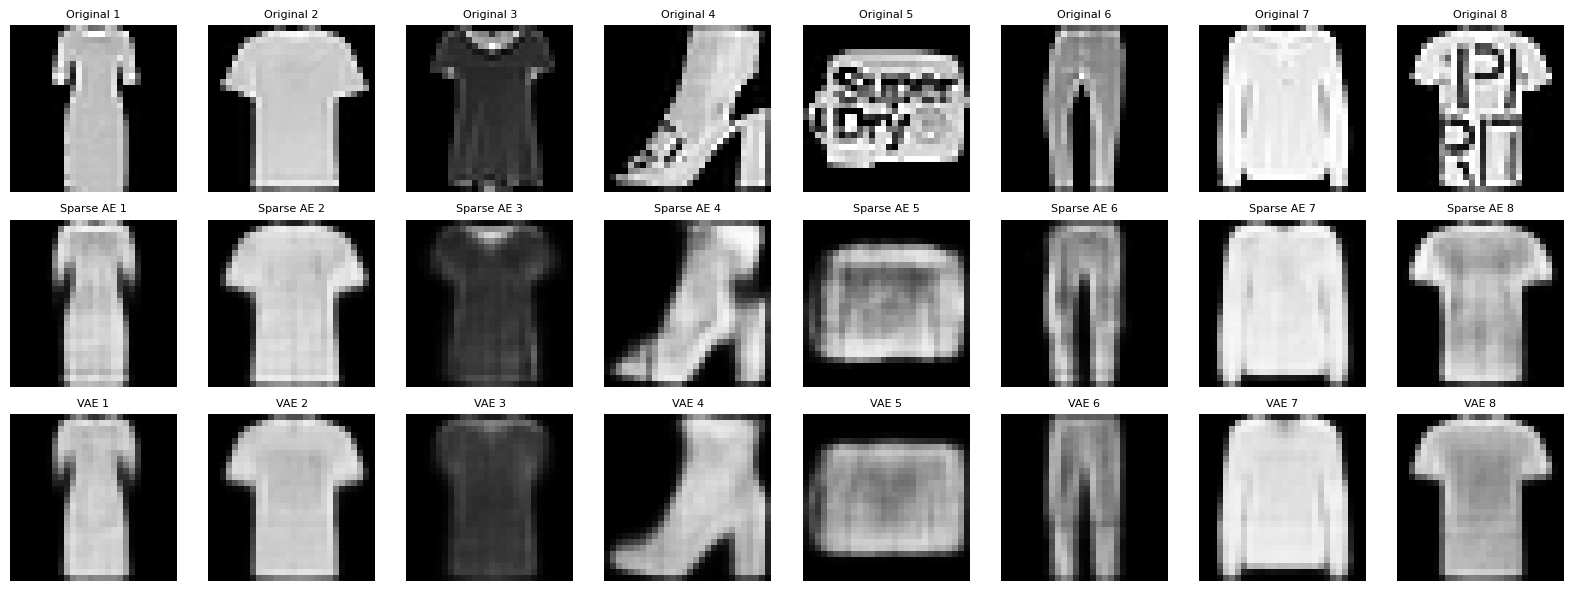

In [13]:
n = 8

images = (
    list(sparse_targets[:n])
    + list(sparse_outputs[:n])
    + list(vae_outputs[:n])
)

titles = (
    [f"Original {i+1}" for i in range(n)]
    + [f"Sparse AE {i+1}" for i in range(n)]
    + [f"VAE {i+1}" for i in range(n)]
)

show_grid(
    images,
    titles,
    rows=3,
    cols=n,
    figsize=(16, 6)
)

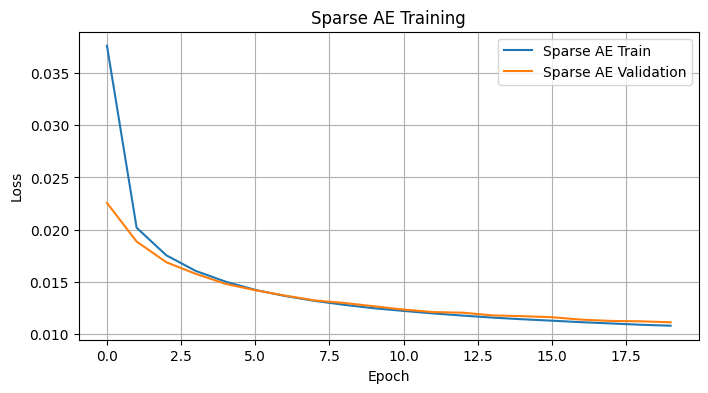

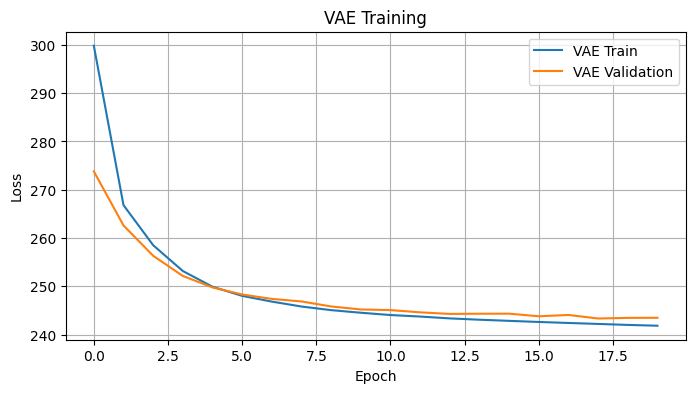

In [14]:
plt.figure(figsize=(8, 4))

plt.plot(
    sparse_history["train"],
    label="Sparse AE Train"
)
plt.plot(
    sparse_history["val"],
    label="Sparse AE Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Sparse AE Training")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 4))

plt.plot(
    vae_history["train"],
    label="VAE Train"
)
plt.plot(
    vae_history["val"],
    label="VAE Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training")
plt.legend()
plt.grid()
plt.show()

In [15]:
LATENT_DIM = 100


class VanillaGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(LATENT_DIM, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.model(z).view(-1, 1, 28, 28)


class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = x.view(x.size(0), 784)
        return self.model(x)


class DCGANGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(
                LATENT_DIM, 128, 7, 1, 0, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                128, 64, 4, 2, 1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(
                64, 1, 4, 2, 1, bias=False
            ),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.model(z)


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 1, 7, 1, 0)
        )

    def forward(self, x):
        return self.model(x).view(-1, 1)

In [ ]:
import time


def sample_noise(batch_size, is_dcgan=False):
    if is_dcgan:
        return torch.randn(
            batch_size, LATENT_DIM, 1, 1, device=DEVICE
        )

    return torch.randn(batch_size, LATENT_DIM, device=DEVICE)


def train_gan(generator, discriminator, loader, is_dcgan=False):
    optimizer_G = torch.optim.Adam(
        generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
    )

    optimizer_D = torch.optim.Adam(
        discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
    )

    criterion = nn.BCEWithLogitsLoss()

    history = {
        "G": [],
        "D": [],
        "epoch_time": []
    }

    for epoch in range(1, MAX_EPOCHS + 1):
        start_time = time.time()

        generator.train()
        discriminator.train()

        total_g_loss = 0.0
        total_d_loss = 0.0
        total_batches = 0

        for images, _ in loader:
            real_images = images.to(DEVICE)
            batch_size = real_images.size(0)

            real_labels = torch.ones(
                batch_size, 1, device=DEVICE
            )
            fake_labels = torch.zeros(
                batch_size, 1, device=DEVICE
            )

            # Train Discriminator
            optimizer_D.zero_grad(set_to_none=True)

            real_output = discriminator(real_images)
            real_loss = criterion(real_output, real_labels)

            noise = sample_noise(batch_size, is_dcgan)
            fake_images = generator(noise)

            fake_output = discriminator(fake_images.detach())
            fake_loss = criterion(fake_output, fake_labels)

            d_loss = real_loss + fake_loss
            d_loss.backward()
            optimizer_D.step()

            # Train Generator
            optimizer_G.zero_grad(set_to_none=True)

            noise = sample_noise(batch_size, is_dcgan)
            generated_images = generator(noise)

            fake_output = discriminator(generated_images)
            g_loss = criterion(fake_output, real_labels)

            g_loss.backward()
            optimizer_G.step()

            total_d_loss += d_loss.item()
            total_g_loss += g_loss.item()
            total_batches += 1

        avg_d_loss = total_d_loss / total_batches
        avg_g_loss = total_g_loss / total_batches
        epoch_time = time.time() - start_time

        history["D"].append(avg_d_loss)
        history["G"].append(avg_g_loss)
        history["epoch_time"].append(epoch_time)

        print(
            f"Epoch {epoch:02d} | "
            f"D Loss: {avg_d_loss:.4f} | "
            f"G Loss: {avg_g_loss:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    return generator, discriminator, history

In [17]:
vanilla_g = VanillaGenerator().to(DEVICE)
vanilla_d = VanillaDiscriminator().to(DEVICE)

vanilla_g, vanilla_d, vanilla_gan_history = train_gan(
    vanilla_g,
    vanilla_d,
    train_loader,
    is_dcgan=False
)


dcgan_g = DCGANGenerator().to(DEVICE)
dcgan_d = DCGANDiscriminator().to(DEVICE)

dcgan_g, dcgan_d, dcgan_history = train_gan(
    dcgan_g,
    dcgan_d,
    train_loader,
    is_dcgan=True
)

Epoch 01 | D Loss: 0.5043 | G Loss: 2.6500 | Time: 21.98s
Epoch 02 | D Loss: 0.3851 | G Loss: 3.8984 | Time: 21.07s
Epoch 03 | D Loss: 0.3878 | G Loss: 3.9988 | Time: 20.92s
Epoch 04 | D Loss: 0.4796 | G Loss: 3.0204 | Time: 20.58s
Epoch 05 | D Loss: 0.4410 | G Loss: 3.3143 | Time: 20.91s
Epoch 06 | D Loss: 0.6081 | G Loss: 2.5454 | Time: 21.23s
Epoch 07 | D Loss: 0.5719 | G Loss: 2.5611 | Time: 20.78s
Epoch 08 | D Loss: 0.7015 | G Loss: 2.1312 | Time: 21.59s
Epoch 09 | D Loss: 0.6799 | G Loss: 2.0173 | Time: 20.12s
Epoch 10 | D Loss: 0.6800 | G Loss: 2.2791 | Time: 20.14s
Epoch 11 | D Loss: 0.7277 | G Loss: 2.0395 | Time: 19.76s
Epoch 12 | D Loss: 0.7431 | G Loss: 1.9740 | Time: 21.00s
Epoch 13 | D Loss: 0.7092 | G Loss: 2.0152 | Time: 21.16s
Epoch 14 | D Loss: 0.8175 | G Loss: 1.7725 | Time: 20.76s
Epoch 15 | D Loss: 0.8550 | G Loss: 1.6785 | Time: 22.93s
Epoch 16 | D Loss: 0.8712 | G Loss: 1.6527 | Time: 20.21s
Epoch 17 | D Loss: 0.8811 | G Loss: 1.6063 | Time: 20.64s
Epoch 18 | D L

Vanilla GAN


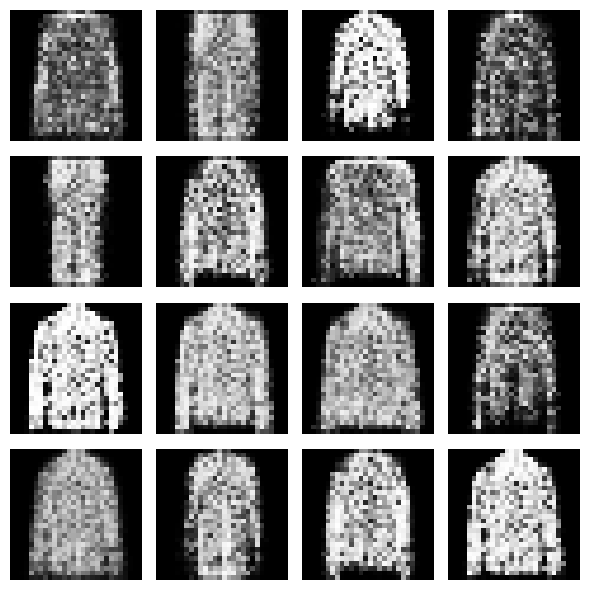

DCGAN


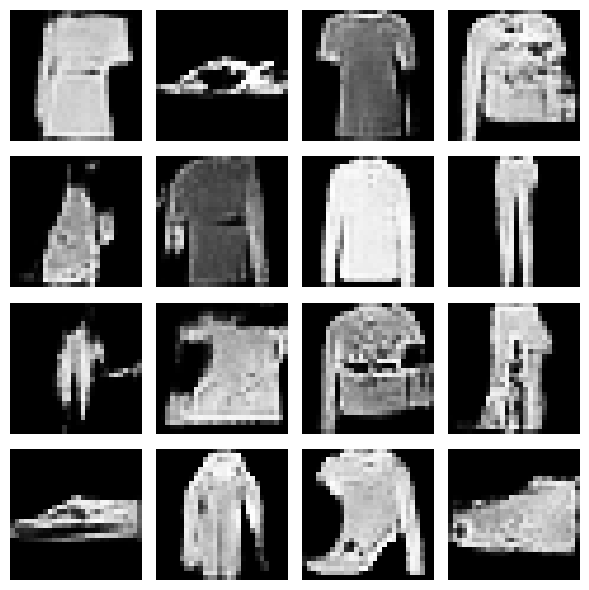

In [18]:
vanilla_g.eval()
dcgan_g.eval()

with torch.no_grad():
    vanilla_samples = vanilla_g(
        sample_noise(16, is_dcgan=False)
    ).cpu()

    dcgan_samples = dcgan_g(
        sample_noise(16, is_dcgan=True)
    ).cpu()

print("Vanilla GAN")
show_grid(
    list(vanilla_samples),
    rows=4,
    cols=4,
    figsize=(6, 6)
)

print("DCGAN")
show_grid(
    list(dcgan_samples),
    rows=4,
    cols=4,
    figsize=(6, 6)
)

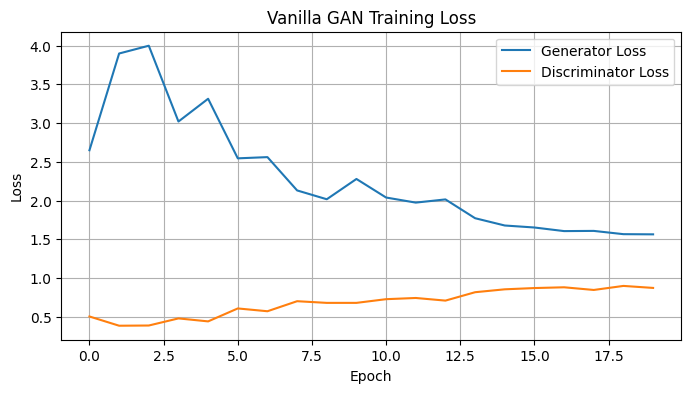

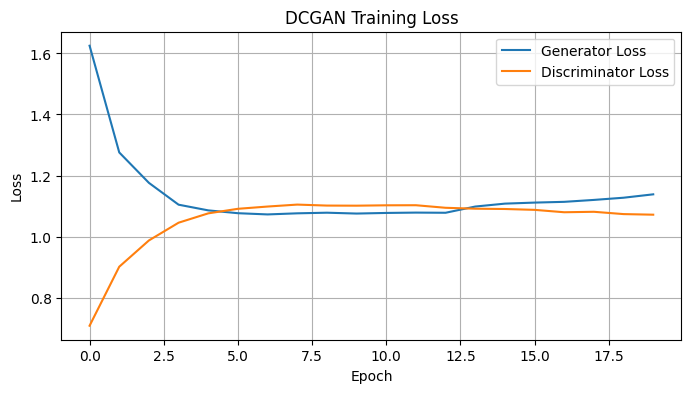

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(
    vanilla_gan_history["G"],
    label="Generator Loss"
)
plt.plot(
    vanilla_gan_history["D"],
    label="Discriminator Loss"
)
plt.title("Vanilla GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(
    dcgan_history["G"],
    label="Generator Loss"
)
plt.plot(
    dcgan_history["D"],
    label="Discriminator Loss"
)
plt.title("DCGAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [23]:
import math
import time

DIFFUSION_STEPS = 100
TIME_EMBED_DIM = 64

def sinusoidal_embedding(t, dim):
    half_dim = dim // 2

    scale = torch.exp(
        torch.arange(half_dim, device=t.device) *
        (-math.log(10000) / (half_dim - 1))
    )

    emb = t.float().unsqueeze(1) * scale.unsqueeze(0)

    return torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)


class DDPMDenoiser(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(784 + TIME_EMBED_DIM, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, 784)
        )

    def forward(self, x, t):
        x = x.view(x.size(0), 784)
        t_emb = sinusoidal_embedding(t, TIME_EMBED_DIM)

        combined = torch.cat([x, t_emb], dim=1)

        predicted_noise = self.network(combined)

        return predicted_noise.view(-1, 1, 28, 28)


ddpm = DDPMDenoiser().to(DEVICE)

In [24]:
betas = torch.linspace(
    1e-4, 0.02, DIFFUSION_STEPS, device=DEVICE
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

In [25]:
def train_ddpm(model, train_loader):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    history = []

    for epoch in range(MAX_EPOCHS):
        model.train()

        total_loss = 0
        start_time = time.time()

        for images, _ in train_loader:
            images = images.to(DEVICE) * 2 - 1

            batch_size = images.size(0)

            t = torch.randint(
                0, DIFFUSION_STEPS,
                (batch_size,), device=DEVICE
            )

            noise = torch.randn_like(images)

            noise_factor = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
            remaining_noise = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

            noisy_images = (
                noise_factor * images +
                remaining_noise * noise
            )

            predicted_noise = model(noisy_images, t)

            loss = criterion(predicted_noise, noise)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_time = time.time() - start_time

        history.append({
            "loss": avg_loss,
            "epoch_time": epoch_time
        })

        print(
            f"Epoch {epoch + 1:02d} | "
            f"DDPM Loss: {avg_loss:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    return model, history

In [26]:
ddpm, ddpm_history = train_ddpm(ddpm, train_loader)

Epoch 01 | DDPM Loss: 0.8113 | Time: 22.70s
Epoch 02 | DDPM Loss: 0.6707 | Time: 22.60s
Epoch 03 | DDPM Loss: 0.6230 | Time: 20.60s
Epoch 04 | DDPM Loss: 0.5991 | Time: 21.57s
Epoch 05 | DDPM Loss: 0.5833 | Time: 16.52s
Epoch 06 | DDPM Loss: 0.5729 | Time: 16.36s
Epoch 07 | DDPM Loss: 0.5657 | Time: 16.44s
Epoch 08 | DDPM Loss: 0.5583 | Time: 17.34s
Epoch 09 | DDPM Loss: 0.5542 | Time: 16.66s
Epoch 10 | DDPM Loss: 0.5518 | Time: 16.67s
Epoch 11 | DDPM Loss: 0.5488 | Time: 16.22s
Epoch 12 | DDPM Loss: 0.5487 | Time: 15.91s
Epoch 13 | DDPM Loss: 0.5435 | Time: 16.24s
Epoch 14 | DDPM Loss: 0.5428 | Time: 16.26s
Epoch 15 | DDPM Loss: 0.5403 | Time: 15.89s
Epoch 16 | DDPM Loss: 0.5398 | Time: 16.16s
Epoch 17 | DDPM Loss: 0.5401 | Time: 17.77s
Epoch 18 | DDPM Loss: 0.5394 | Time: 15.94s
Epoch 19 | DDPM Loss: 0.5374 | Time: 16.39s
Epoch 20 | DDPM Loss: 0.5354 | Time: 16.14s


In [27]:
@torch.no_grad()
def sample_ddpm(model, num_samples=16):
    model.eval()

    x = torch.randn(
        num_samples, 1, 28, 28, device=DEVICE
    )

    trajectory = []
    selected_steps = [99, 79, 59, 39, 19, 0]

    for t in reversed(range(DIFFUSION_STEPS)):
        timestep = torch.full(
            (num_samples,), t,
            device=DEVICE, dtype=torch.long
        )

        predicted_noise = model(x, timestep)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        mean = (
            1 / torch.sqrt(alpha)
        ) * (
            x - (beta / torch.sqrt(1 - alpha_bar)) * predicted_noise
        )

        if t > 0:
            noise = torch.randn_like(x)
            x = mean + torch.sqrt(beta) * noise
        else:
            x = mean

        if t in selected_steps:
            trajectory.append((t, x[0:1].clone()))

    images = ((x.clamp(-1, 1) + 1) / 2)

    return images, trajectory

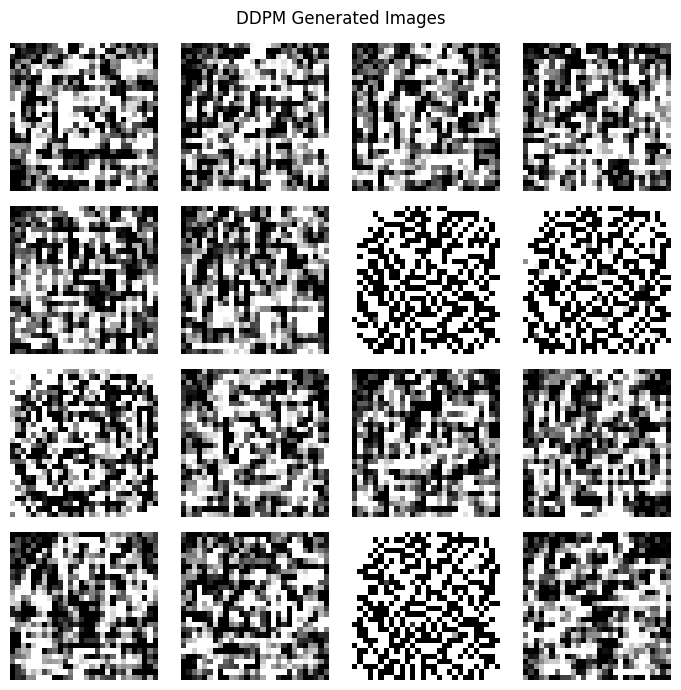

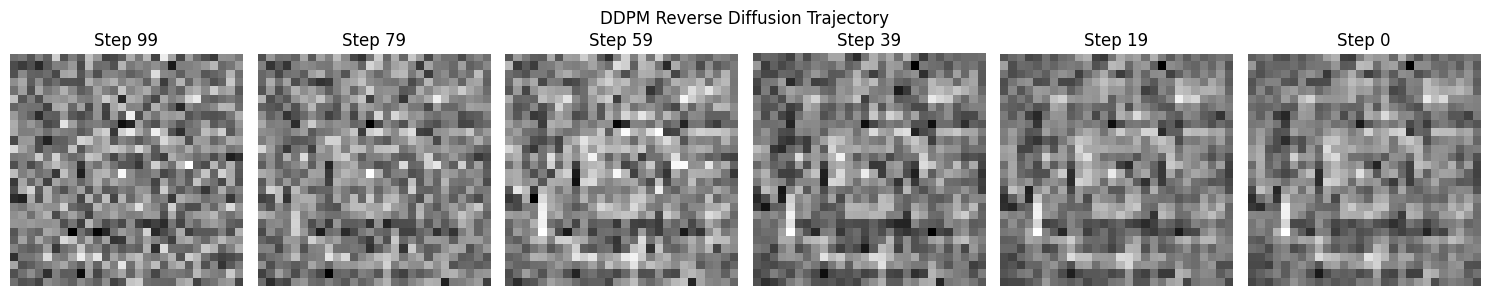

In [28]:
ddpm_images, ddpm_trajectory = sample_ddpm(ddpm, num_samples=16)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        ddpm_images[i].squeeze().cpu().numpy(),
        cmap="gray"
    )
    ax.axis("off")

plt.suptitle("DDPM Generated Images")
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, (step, image) in zip(axes, ddpm_trajectory):
    ax.imshow(
        ((image.squeeze().cpu().numpy() + 1) / 2),
        cmap="gray"
    )
    ax.set_title(f"Step {step}")
    ax.axis("off")

plt.suptitle("DDPM Reverse Diffusion Trajectory")
plt.tight_layout()
plt.show()

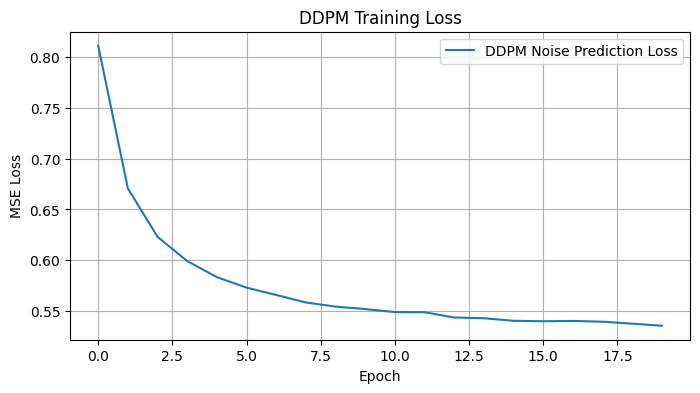

In [29]:
plt.figure(figsize=(8, 4))

plt.plot(
    [item["loss"] for item in ddpm_history],
    label="DDPM Noise Prediction Loss"
)

plt.title("DDPM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
@torch.no_grad()
def generate_model_samples(model_name, n_samples):
    if model_name == "VAE":
        z = torch.randn(n_samples, 64, device=DEVICE)
        images = vae.decode(z)

    elif model_name == "Vanilla GAN":
        z = sample_noise(n_samples)
        images = vanilla_g(z)

    elif model_name == "DCGAN":
        z = sample_noise(n_samples, is_dcgan=True)
        images = dcgan_g(z)

    elif model_name == "DDPM":
        images, _ = sample_ddpm(ddpm, num_samples=n_samples)

    return images.view(-1, 1, 28, 28).clamp(0, 1)


def to_fid_input(images):
    images = images.repeat(1, 3, 1, 1)
    images = (images * 255).round().clamp(0, 255)
    return images.to(torch.uint8)


N_FID = 512

real_images = []
remaining = N_FID

for images, _ in test_loader:
    take = min(remaining, images.size(0))
    real_images.append(images[:take])
    remaining -= take

    if remaining == 0:
        break

real_images = torch.cat(real_images).to(DEVICE)

models_to_evaluate = [
    "VAE",
    "Vanilla GAN",
    "DCGAN",
    "DDPM"
]

fid_results = {}

for model_name in models_to_evaluate:
    print(f"\nMenghitung FID: {model_name}")

    fid = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(DEVICE)

    fid.update(to_fid_input(real_images), real=True)

    generated = generate_model_samples(model_name, N_FID)

    fid.update(to_fid_input(generated), real=False)

    fid_results[model_name] = fid.compute().item()

    print(f"{model_name} FID: {fid_results[model_name]:.4f}")

    del fid


Menghitung FID: VAE


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\user1/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [01:00<00:00, 1.59MB/s]


VAE FID: 120.3116

Menghitung FID: Vanilla GAN
Vanilla GAN FID: 212.5391

Menghitung FID: DCGAN
DCGAN FID: 63.7001

Menghitung FID: DDPM
DDPM FID: 384.8438


In [35]:
import pandas as pd

fid_table = pd.DataFrame({
    "Model": fid_results.keys(),
    "FID Score": fid_results.values()
})

display(fid_table.sort_values("FID Score"))

,Model,FID Score
2,DCGAN,63.700150
0,VAE,120.311607
1,Vanilla GAN,212.539062
3,DDPM,384.843842


In [ ]:
import time

BATCH_SIZE = 64
WARMUP = 2
REPEATS = 5

test_images, _ = next(iter(test_loader))
test_images = test_images[:BATCH_SIZE].to(DEVICE)

assert test_images.size(0) == BATCH_SIZE

@torch.inference_mode()
def sample_ddpm_benchmark(model, num_samples=64):
    model.eval()

    x = torch.randn(
        num_samples, 1, 28, 28, device=DEVICE
    )

    for t in reversed(range(DIFFUSION_STEPS)):
        timestep = torch.full(
            (num_samples,), t,
            device=DEVICE, dtype=torch.long
        )

        predicted_noise = model(x, timestep)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        mean = (1 / torch.sqrt(alpha)) * (
            x - (beta / torch.sqrt(1 - alpha_bar)) * predicted_noise
        )

        if t > 0:
            x = mean + torch.sqrt(beta) * torch.randn_like(x)
        else:
            x = mean

    return x


def benchmark_latency(name, model, inference_function):
    model.eval()

    for _ in range(WARMUP):
        inference_function()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    times = []

    for _ in range(REPEATS):
        start = time.perf_counter()

        inference_function()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        times.append(time.perf_counter() - start)

    avg_time = sum(times) / len(times)

    print(f"{name}: {avg_time * 1000:.2f} ms / batch 64")

    return avg_time * 1000


latency_results = {}

latency_results["Vanilla AE"] = benchmark_latency(
    "Vanilla AE",
    vanilla_ae,
    lambda: vanilla_ae(test_images)
)

latency_results["Sparse AE"] = benchmark_latency(
    "Sparse AE",
    sparse_ae,
    lambda: sparse_ae(test_images)
)

latency_results["VAE"] = benchmark_latency(
    "VAE",
    vae,
    lambda: vae(test_images)
)

latency_results["Vanilla GAN"] = benchmark_latency(
    "Vanilla GAN",
    vanilla_g,
    lambda: vanilla_g(sample_noise(BATCH_SIZE))
)

latency_results["DCGAN"] = benchmark_latency(
    "DCGAN",
    dcgan_g,
    lambda: dcgan_g(sample_noise(BATCH_SIZE, is_dcgan=True))
)

latency_results["DDPM"] = benchmark_latency(
    "DDPM",
    ddpm,
    lambda: sample_ddpm_benchmark(ddpm, BATCH_SIZE)
)

Vanilla AE: 1.15 ms / batch 64
Sparse AE: 0.95 ms / batch 64
VAE: 1.22 ms / batch 64
Vanilla GAN: 1.11 ms / batch 64
DCGAN: 15.38 ms / batch 64
DDPM: 330.94 ms / batch 64


In [46]:
latency_table = pd.DataFrame({
    "Model": latency_results.keys(),
    "Latency (ms/batch 64)": latency_results.values()
})

display(
    latency_table.sort_values("Latency (ms/batch 64)")
)

,Model,Latency (ms/batch 64)
1,Sparse AE,0.94742
3,Vanilla GAN,1.11414
0,Vanilla AE,1.15388
2,VAE,1.22204
4,DCGAN,15.37934
5,DDPM,330.93538


In [ ]:
alphas_interp = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

interp_images, _ = next(iter(test_loader))
x_a = interp_images[0:1].to(DEVICE).view(1, 784)
x_b = interp_images[1:2].to(DEVICE).view(1, 784)

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()
vanilla_g.eval()
dcgan_g.eval()

interpolation_results = {}

with torch.no_grad():

    # 1. Vanilla AE
    z_a = vanilla_ae.encode(x_a)
    z_b = vanilla_ae.encode(x_b)

    images = []
    for alpha in alphas_interp:
        z = (1 - alpha) * z_a + alpha * z_b
        output = torch.sigmoid(
            vanilla_ae.decoder2(
                F.relu(vanilla_ae.decoder1(z))
            )
        )
        images.append(output.view(28, 28).cpu())

    interpolation_results["Vanilla AE"] = images

    # 2. Sparse AE
    z_a = sparse_ae.encode(x_a)
    z_b = sparse_ae.encode(x_b)

    images = []
    for alpha in alphas_interp:
        z = (1 - alpha) * z_a + alpha * z_b
        output = torch.sigmoid(
            sparse_ae.decoder2(
                F.relu(sparse_ae.decoder1(z))
            )
        )
        images.append(output.view(28, 28).cpu())

    interpolation_results["Sparse AE"] = images

    # 3. VAE
    mu_a, _ = vae.encode(x_a)
    mu_b, _ = vae.encode(x_b)

    images = []
    for alpha in alphas_interp:
        z = (1 - alpha) * mu_a + alpha * mu_b
        output = vae.decode(z)
        images.append(output.view(28, 28).cpu())

    interpolation_results["VAE"] = images

    # 4. Vanilla GAN
    torch.manual_seed(SEED)
    z_a = torch.randn(1, LATENT_DIM, device=DEVICE)
    z_b = torch.randn(1, LATENT_DIM, device=DEVICE)

    images = []
    for alpha in alphas_interp:
        z = (1 - alpha) * z_a + alpha * z_b
        output = vanilla_g(z)
        images.append(output.view(28, 28).cpu())

    interpolation_results["Vanilla GAN"] = images

    # 5. DCGAN
    torch.manual_seed(SEED)
    z_a = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)
    z_b = torch.randn(1, LATENT_DIM, 1, 1, device=DEVICE)

    images = []
    for alpha in alphas_interp:
        z = (1 - alpha) * z_a + alpha * z_b
        output = dcgan_g(z)
        images.append(output.view(28, 28).cpu())

    interpolation_results["DCGAN"] = images

Latent interpolation selesai.


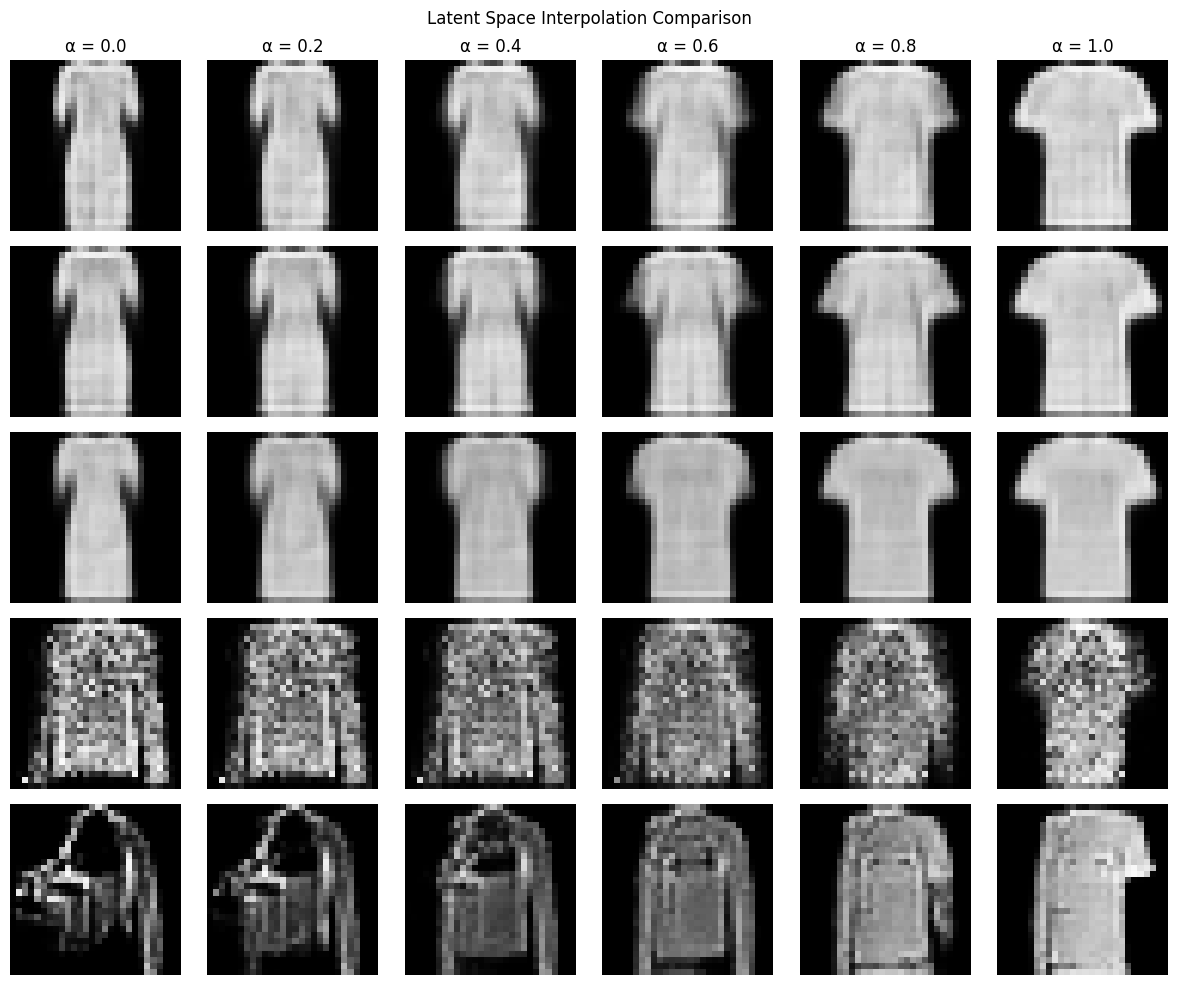

In [48]:
fig, axes = plt.subplots(5, 6, figsize=(12, 10))

for row, (model_name, images) in enumerate(
    interpolation_results.items()
):
    for col, image in enumerate(images):
        axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                f"α = {alphas_interp[col]}"
            )

    axes[row, 0].set_ylabel(
        model_name,
        fontsize=10,
        rotation=90,
        labelpad=15
    )

plt.suptitle("Latent Space Interpolation Comparison")
plt.tight_layout()
plt.show()

In [49]:
results_summary = pd.DataFrame([
    {
        "Model": "Vanilla AE",
        "FID": None,
        "Latency (ms/batch 64)": latency_results["Vanilla AE"]
    },
    {
        "Model": "Sparse AE",
        "FID": None,
        "Latency (ms/batch 64)": latency_results["Sparse AE"]
    },
    {
        "Model": "VAE",
        "FID": fid_results["VAE"],
        "Latency (ms/batch 64)": latency_results["VAE"]
    },
    {
        "Model": "Vanilla GAN",
        "FID": fid_results["Vanilla GAN"],
        "Latency (ms/batch 64)": latency_results["Vanilla GAN"]
    },
    {
        "Model": "DCGAN",
        "FID": fid_results["DCGAN"],
        "Latency (ms/batch 64)": latency_results["DCGAN"]
    },
    {
        "Model": "DDPM",
        "FID": fid_results["DDPM"],
        "Latency (ms/batch 64)": latency_results["DDPM"]
    }
])

display(results_summary)

,Model,FID,Latency (ms/batch 64)
0,Vanilla AE,NaN,1.15388
1,Sparse AE,NaN,0.94742
2,VAE,120.311607,1.22204
3,Vanilla GAN,212.539062,1.11414
4,DCGAN,63.700150,15.37934
5,DDPM,384.843842,330.93538


In [ ]:
results_summary.to_csv(
    "hasil_perbandingan_model.csv",
    index=False
)

In [52]:
print("Frozen Latent Decoder:")
print(reconstruction_metrics(frozen_outputs, targets))

print("\nSparse AE:")
print(reconstruction_metrics(sparse_outputs, sparse_targets))

print("\nVAE:")
print(reconstruction_metrics(vae_outputs, vae_targets))

Frozen Latent Decoder:
{'MSE': 0.01710904762148857, 'PSNR (dB)': 18.40536880493164, 'SSIM': 0.6569328308105469}

Sparse AE:
{'MSE': 0.01015983335673809, 'PSNR (dB)': 20.871383666992188, 'SSIM': 0.7542911171913147}

VAE:
{'MSE': 0.01368155051022768, 'PSNR (dB)': 19.448312759399414, 'SSIM': 0.6991170048713684}


In [82]:
reconstruction_results = pd.DataFrame([
    {
        "Model": "Frozen Latent Decoder",
        **reconstruction_metrics(frozen_outputs, targets)
    },
    {
        "Model": "Sparse AE",
        **reconstruction_metrics(sparse_outputs, sparse_targets)
    },
    {
        "Model": "VAE",
        **reconstruction_metrics(vae_outputs, vae_targets)
    }
])

display(reconstruction_results)

reconstruction_results.to_csv(
    "hasil_reconstruction.csv",
    index=False
)

,Model,MSE,PSNR (dB),SSIM
0,Frozen Latent Decoder,0.017109,18.405369,0.656933
1,Sparse AE,0.010160,20.871384,0.754291
2,VAE,0.013682,19.448313,0.699117


In [55]:
print("Sparse AE:", sparse_history)
print("\nVAE:", vae_history)
print("\nVanilla GAN:", vanilla_gan_history)
print("\nDCGAN:", dcgan_history)
print("\nDDPM:", ddpm_history)

Sparse AE: {'train': [0.03761162308497088, 0.02018928682591234, 0.01755014066823891, 0.01604300706940038, 0.015025651022791863, 0.014237692707351276, 0.013655449464917183, 0.013185415116803987, 0.012807887941598893, 0.012481932078089033, 0.012224224245973995, 0.011983963955725943, 0.011776850704635893, 0.011585103826863424, 0.011426683286471026, 0.011290003134735993, 0.011145115925797394, 0.011024011849292687, 0.01090077759538378, 0.01080810507280486], 'val': [0.0225646607705525, 0.01886774427337306, 0.016885957189968655, 0.01576849580130407, 0.014815133486475264, 0.014204637291175978, 0.013693597356123584, 0.013230975674731391, 0.012983739114233426, 0.012669058462338787, 0.012354108231408256, 0.012114634715020656, 0.012054466683949744, 0.011795374403042453, 0.011722336991557053, 0.011622926245842661, 0.01138894327942814, 0.011266010417469911, 0.011230057880282402, 0.011134455895849637]}

VAE: {'train': [299.8244237234933, 266.80027713448663, 258.5013691231864, 253.155177507673, 249.90

In [83]:
training_times = {
    "Vanilla AE": None,
    "Sparse AE": None,
    "VAE": None,
    "Vanilla GAN": sum(vanilla_gan_history["epoch_time"]),
    "DCGAN": sum(dcgan_history["epoch_time"]),
    "DDPM": sum(epoch["epoch_time"] for epoch in ddpm_history)
}

training_time_table = pd.DataFrame([
    {
        "Model": name,
        "Training Time (seconds)": duration
    }
    for name, duration in training_times.items()
])

display(training_time_table)

training_time_table.to_csv(
    "hasil_training_time.csv",
    index=False
)

,Model,Training Time (seconds)
0,Vanilla AE,NaN
1,Sparse AE,NaN
2,VAE,NaN
3,Vanilla GAN,415.858845
4,DCGAN,3813.673836
5,DDPM,350.385939


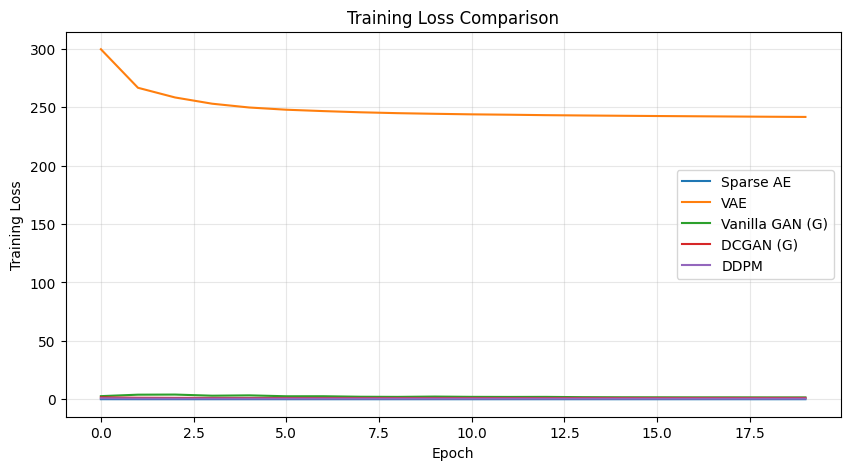

In [57]:
plt.figure(figsize=(10, 5))

plt.plot(sparse_history["train"], label="Sparse AE")
plt.plot(vae_history["train"], label="VAE")
plt.plot(vanilla_gan_history["G"], label="Vanilla GAN (G)")
plt.plot(dcgan_history["G"], label="DCGAN (G)")
plt.plot(
    [epoch["loss"] for epoch in ddpm_history],
    label="DDPM"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [85]:
final_results = pd.DataFrame([
    {
        "Model": "Vanilla AE",
        "MSE": 0.017109,
        "PSNR": 18.4054,
        "SSIM": 0.6569,
        "FID": None,
        "Latency (ms/batch 64)": 1.15388,
        "Training Time (s)": None
    },
    {
        "Model": "Sparse AE",
        "MSE": 0.010160,
        "PSNR": 20.8714,
        "SSIM": 0.7543,
        "FID": None,
        "Latency (ms/batch 64)": 0.94742,
        "Training Time (s)": None
    },
    {
        "Model": "VAE",
        "MSE": 0.013682,
        "PSNR": 19.4483,
        "SSIM": 0.6991,
        "FID": 120.31,
        "Latency (ms/batch 64)": 1.22204,
        "Training Time (s)": None
    },
    {
        "Model": "Vanilla GAN",
        "MSE": None,
        "PSNR": None,
        "SSIM": None,
        "FID": 212.54,
        "Latency (ms/batch 64)": 1.11414,
        "Training Time (s)": sum(vanilla_gan_history["epoch_time"])
    },
    {
        "Model": "DCGAN",
        "MSE": None,
        "PSNR": None,
        "SSIM": None,
        "FID": 63.70,
        "Latency (ms/batch 64)": 15.37934,
        "Training Time (s)": sum(dcgan_history["epoch_time"])
    },
    {
        "Model": "DDPM",
        "MSE": None,
        "PSNR": None,
        "SSIM": None,
        "FID": 384.84,
        "Latency (ms/batch 64)": 330.93538,
        "Training Time (s)": sum(
            epoch["epoch_time"] for epoch in ddpm_history
        )
    }
])

display(final_results.round(4))

final_results.to_csv("final_results.csv", index=False)

,Model,MSE,PSNR,SSIM,FID,Latency (ms/batch 64),Training Time (s)
0,Vanilla AE,0.0171,18.4054,0.6569,NaN,1.1539,NaN
1,Sparse AE,0.0102,20.8714,0.7543,NaN,0.9474,NaN
2,VAE,0.0137,19.4483,0.6991,120.31,1.2220,NaN
3,Vanilla GAN,NaN,NaN,NaN,212.54,1.1141,415.8588
4,DCGAN,NaN,NaN,NaN,63.70,15.3793,3813.6738
5,DDPM,NaN,NaN,NaN,384.84,330.9354,350.3859


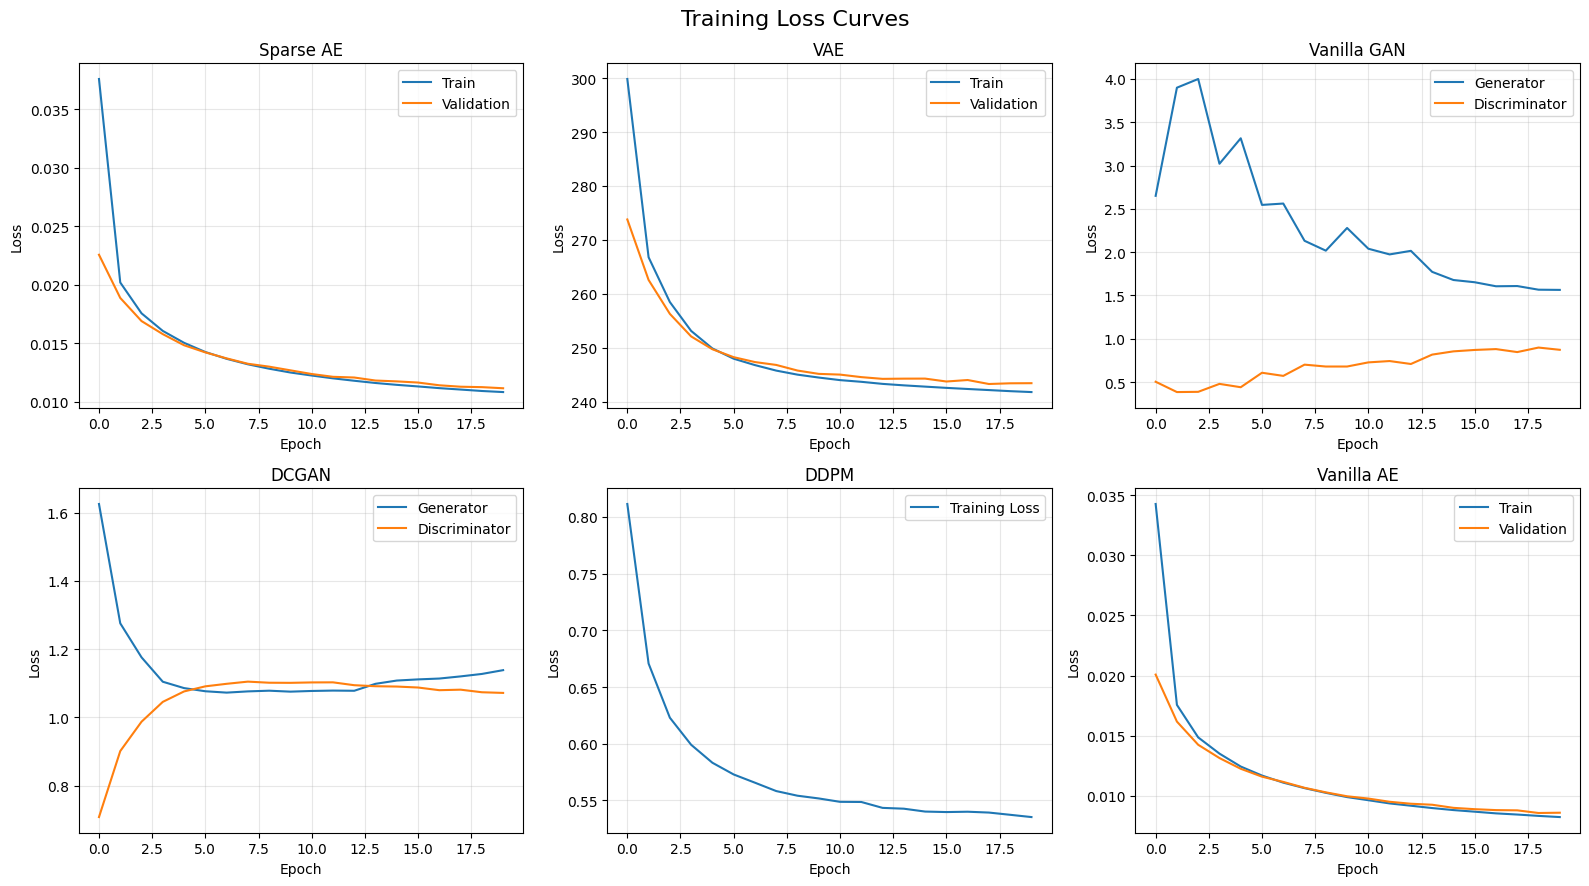

In [86]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Sparse AE
axes[0].plot(sparse_history["train"], label="Train")
axes[0].plot(sparse_history["val"], label="Validation")
axes[0].set_title("Sparse AE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# VAE
axes[1].plot(vae_history["train"], label="Train")
axes[1].plot(vae_history["val"], label="Validation")
axes[1].set_title("VAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Vanilla GAN
axes[2].plot(vanilla_gan_history["G"], label="Generator")
axes[2].plot(vanilla_gan_history["D"], label="Discriminator")
axes[2].set_title("Vanilla GAN")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(alpha=0.3)

# DCGAN
axes[3].plot(dcgan_history["G"], label="Generator")
axes[3].plot(dcgan_history["D"], label="Discriminator")
axes[3].set_title("DCGAN")
axes[3].set_xlabel("Epoch")
axes[3].set_ylabel("Loss")
axes[3].legend()
axes[3].grid(alpha=0.3)

# DDPM
ddpm_losses = [epoch["loss"] for epoch in ddpm_history]
axes[4].plot(ddpm_losses, label="Training Loss")
axes[4].set_title("DDPM")
axes[4].set_xlabel("Epoch")
axes[4].set_ylabel("Loss")
axes[4].legend()
axes[4].grid(alpha=0.3)

# Vanilla AE
axes[5].plot(
    vanilla_ae_history["train"],
    label="Train"
)
axes[5].plot(
    vanilla_ae_history["val"],
    label="Validation"
)
axes[5].set_title("Vanilla AE")
axes[5].set_xlabel("Epoch")
axes[5].set_ylabel("Loss")
axes[5].legend()
axes[5].grid(alpha=0.3)

plt.suptitle("Training Loss Curves", fontsize=16)
plt.tight_layout()
plt.savefig("figur5_training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

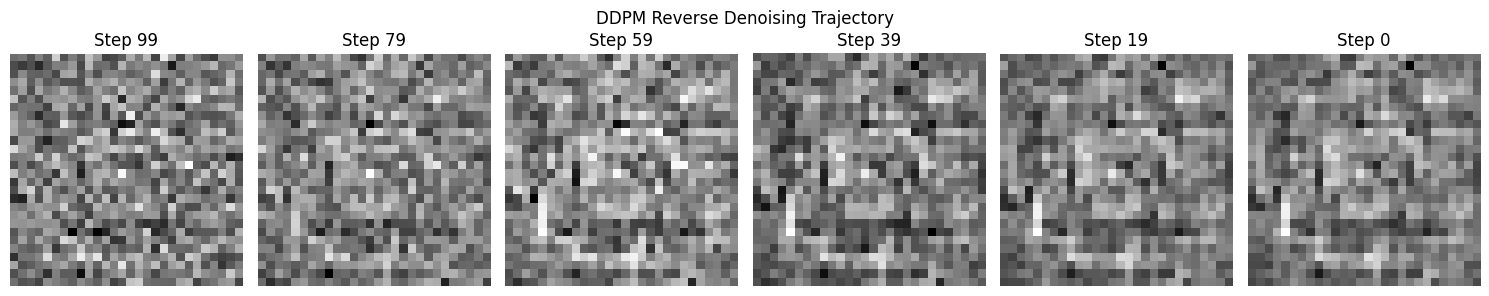

In [64]:
fig, axes = plt.subplots(1, len(ddpm_trajectory), figsize=(15, 3))

for i, (timestep, image) in enumerate(ddpm_trajectory):
    image = image.detach().cpu().squeeze().numpy()

    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Step {timestep}")
    axes[i].axis("off")

plt.suptitle("DDPM Reverse Denoising Trajectory")
plt.tight_layout()

plt.savefig(
    "figur5_ddpm_trajectory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()